# Group Pipeline - Ames Housing Preprocessing (Integrated)

**Group ID:** GROUP_ID &nbsp;|&nbsp; **Dataset:** Ames Housing (`train.csv`)

This notebook integrates the six members' preprocessing work for exploratory analysis. Its processed CSV is not used by the individual model notebooks; those notebooks build their own train-fold-fitted pipelines (imputation + one-hot encoding + scaling) so that no information leaks from validation folds.

| Step | Member | Technique |
|---|---|---|
| 1 | MEMBER1 | Handling Missing Data |
| 2 | MEMBER2 | Encoding Categorical Variables |
| 3 | MEMBER3 | Outlier Handling |
| 4 | MEMBER4 | Normalization / Scaling |
| 5 | MEMBER5 | Feature Selection |
| 6 | MEMBER6 | Dimensionality Reduction (PCA) |

## Step 0 - Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('data/raw/train.csv')
df['MSSubClass'] = df['MSSubClass'].astype(str)
df['SalePrice_log'] = np.log1p(df['SalePrice'])
orig_num = [c for c in df.select_dtypes(include='number').columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
print(df.shape, '|', len(orig_num), 'numeric features |', int(df.isnull().sum().sum()), 'missing cells')
df.head()

(1460, 82) | 35 numeric features | 7829 missing cells


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,SalePrice_log
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,NaN,NaN,NaN,0,2,2008,WD,Normal,208500,12.247699
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,NaN,NaN,NaN,0,5,2007,WD,Normal,181500,12.109016
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,NaN,NaN,NaN,0,9,2008,WD,Normal,223500,12.317171
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000,11.849405
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,NaN,NaN,NaN,0,12,2008,WD,Normal,250000,12.429220


## Step 1 (MEMBER1) - Handling missing data

Structural `NA` -> category `None`; absent-feature areas -> 0; `LotFrontage` -> neighbourhood median; remaining numeric -> median; `Electrical` -> mode.

In [2]:
df1 = df.copy()
cat_cols = df1.select_dtypes(exclude='number').columns
none_cols = [c for c in cat_cols if df1[c].isna().any() and c != 'Electrical']
df1[none_cols] = df1[none_cols].fillna('None')
df1['Electrical'] = df1['Electrical'].fillna(df1['Electrical'].mode()[0])
df1['MasVnrArea'] = df1['MasVnrArea'].fillna(0)
df1['LotFrontage'] = df1['LotFrontage'].fillna(df1.groupby('Neighborhood')['LotFrontage'].transform('median')).fillna(df1['LotFrontage'].median())
df1['GarageYrBlt'] = df1['GarageYrBlt'].fillna(df1['GarageYrBlt'].median())
print('Missing cells after step 1:', int(df1.isnull().sum().sum()))

Missing cells after step 1: 0


## Step 2 (MEMBER2) - Encoding categorical variables

Ordered scales -> integers; nominal columns -> one-hot.

In [3]:
quality = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_maps = {
    **{c: quality for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']},
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'LotShape': {'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3},
    'LandSlope': {'Sev': 0, 'Mod': 1, 'Gtl': 2},
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},
    'CentralAir': {'N': 0, 'Y': 1},
}
df2 = df1.copy()
for c, m in ordinal_maps.items():
    df2[c] = df2[c].map(m)
nominal = [c for c in df2.select_dtypes(exclude='number').columns]
df2 = pd.get_dummies(df2, columns=nominal, dtype='int8')
onehot_cols = [c for c in df2.columns if any(c.startswith(n + '_') for n in nominal)]
ordinal_cols = list(ordinal_maps)
print('Ordinal columns:', len(ordinal_cols), '| one-hot columns:', len(onehot_cols), '| total columns:', df2.shape[1])

Ordinal columns: 18 | one-hot columns: 196 | total columns: 252


## Step 3 (MEMBER3) - Outlier handling

A sequential IQR row filter was rejected (it removes 14 % of rows, mostly expensive houses). The pipeline removes only the two documented extreme partial sales and applies `log1p` to strongly right-skewed numeric features.

In [4]:
df3 = df2.copy()
extreme = (df3['GrLivArea'] > 4000) & (df3['SalePrice'] < 300000)
df3 = df3[~extreme].copy()
skewed = [c for c in orig_num if c != 'MSSubClass' and df[c].skew() > 0.75 and df[c].min() >= 0]
for c in skewed:
    df3[c] = np.log1p(df3[c])
print('Rows removed:', int(extreme.sum()), '| rows kept:', len(df3))
print('log1p applied to', len(skewed), 'columns, e.g.', skewed[:6])
print('Max skew of those columns now:', round(df3[skewed].skew().max(), 2), '(was', round(df[skewed].skew().max(), 2), ')')

Rows removed: 2 | rows kept: 1458
log1p applied to 20 columns, e.g. ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF']
Max skew of those columns now: 15.52 (was 24.48 )


## Step 4 (MEMBER4) - Scaling

StandardScaler on the continuous / ordinal numeric columns (one-hot indicators stay 0/1).

In [5]:
from sklearn.preprocessing import StandardScaler
df4 = df3.copy()
scale_cols = [c for c in orig_num if c in df4.columns] + ordinal_cols
df4[scale_cols] = StandardScaler().fit_transform(df4[scale_cols])
print('Scaled', len(scale_cols), 'columns. Mean ~', round(df4[scale_cols].mean().abs().max(), 6), '| std ~', round(df4[scale_cols].std().mean(), 3))

Scaled 53 columns. Mean ~ 0.0 | std ~ 1.0


## Step 5 (MEMBER5) - Feature selection

Drop one feature of each highly correlated pair (|r| > 0.8, keep the one more correlated with price) and numeric features with |r| < 0.05 against log price.

In [6]:
num_feats = [c for c in orig_num if c != 'MSSubClass' and c in df4.columns]
tcorr = df4[num_feats + ['SalePrice_log']].corr()['SalePrice_log'].drop('SalePrice_log')
corr = df4[num_feats].corr()
redundant = set()
for i, a in enumerate(num_feats):
    for b in num_feats[i + 1:]:
        if abs(corr.loc[a, b]) > 0.8:
            redundant.add(a if abs(tcorr[a]) < abs(tcorr[b]) else b)
irrelevant = set(tcorr[tcorr.abs() < 0.05].index)
drop_cols = sorted(redundant | irrelevant)
selected_numeric = [c for c in num_feats if c not in drop_cols]
print('Dropped redundant :', sorted(redundant))
print('Dropped irrelevant:', sorted(irrelevant))
print('Numeric features kept:', len(selected_numeric), 'of', len(num_feats))

Dropped redundant : ['GarageArea', 'TotRmsAbvGrd']
Dropped irrelevant: ['BsmtFinSF2', 'BsmtHalfBath', 'OverallCond', 'YrSold']
Numeric features kept: 29 of 35


## Step 6 (MEMBER6) - Dimensionality reduction (PCA)

In [7]:
from sklearn.decomposition import PCA
pca_cols = selected_numeric + ordinal_cols
Xp = df4[pca_cols].values
pca = PCA(n_components=2, random_state=42)
comp = pca.fit_transform(Xp)
print('Variance explained by 2 components:', round(pca.explained_variance_ratio_.sum() * 100, 1), '%')
full = PCA(random_state=42).fit(Xp)
n90 = int(np.argmax(np.cumsum(full.explained_variance_ratio_) >= 0.9) + 1)
print('Components for 90 % variance:', n90, 'of', len(pca_cols))

Variance explained by 2 components: 28.0 %
Components for 90 % variance: 27 of 47


## Combined pipeline visualization

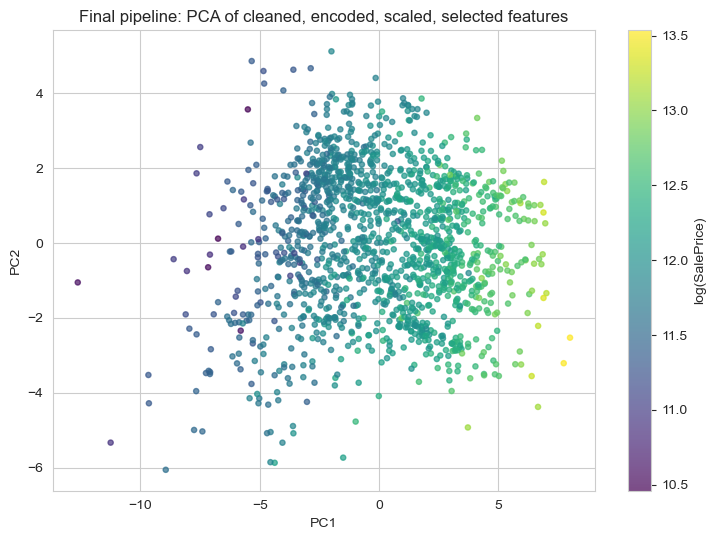

In [8]:
os.makedirs('results/eda_visualizations/GroupPipeline', exist_ok=True)
plt.figure(figsize=(7.5, 5.5))
sc = plt.scatter(comp[:, 0], comp[:, 1], c=df4['SalePrice_log'], cmap='viridis', s=14, alpha=0.7)
plt.colorbar(sc, label='log(SalePrice)'); plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Final pipeline: PCA of cleaned, encoded, scaled, selected features')
plt.tight_layout()
plt.savefig('results/eda_visualizations/GroupPipeline/pipeline_pca.png', dpi=120)
plt.show()

**Interpretation:** the first two principal components explain only part of the variance, and the price gradient along PC1 shows the cleaned size/quality features separate cheap from expensive houses. Treat the plot as a low-dimensional exploratory view. This feature table is separate from the model notebooks, whose preprocessing is fitted inside cross-validation folds.

## Save final processed dataset

In [9]:
keep = ['Id'] + selected_numeric + ordinal_cols + onehot_cols + ['SalePrice', 'SalePrice_log']
final_df = df4[keep].copy()
os.makedirs('results/outputs', exist_ok=True)
final_df.to_csv('results/outputs/ames_processed.csv', index=False)
print('Final dataset shape:', final_df.shape, '| missing cells:', int(final_df.isnull().sum().sum()))
final_df.iloc[:, :8].head()

Final dataset shape: (1458, 246) | missing cells: 0


,Id,LotFrontage,LotArea,OverallQual,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1
0,1,-0.079885,-0.129624,0.658506,1.052959,0.880362,1.207635,0.781657
1,2,0.558193,0.118819,-0.068293,0.158428,-0.428115,-0.805570,0.890540
2,3,0.058613,0.427643,0.658506,0.986698,0.831900,1.135442,0.656962
3,4,-0.325343,0.108651,0.658506,-1.862551,-0.718888,-0.805570,0.386556
4,5,0.708377,0.889295,1.385305,0.953567,0.734975,1.427727,0.756612
